# ДЗ 4. Apache Spark. Оптимізація та SparkUI

## Імпорти

In [1]:
import subprocess
from pathlib import Path

import gdown
from IPython.display import Image, display
from pyspark.sql import SparkSession

## Підготовка даних

In [2]:
DATA_FILE_ID = "1XmmUpuTwNH6YZHZMVRYQe0vJvBy3vQY5"
DATA_PATH = Path("nuek-vuh3.csv")
SCREENSHOTS_DIR = Path("screenshots")
CHROME = "/Applications/Google Chrome.app/Contents/MacOS/Google Chrome"

if not DATA_PATH.exists():
    gdown.download(id=DATA_FILE_ID, output=str(DATA_PATH), quiet=True)
SCREENSHOTS_DIR.mkdir(exist_ok=True)

print(f"{DATA_PATH}: {DATA_PATH.stat().st_size / 1024:.0f} КБ")

nuek-vuh3.csv: 453 КБ


## Спільний код для трьох частин

In [3]:
def create_session():
    """Створює нову Spark-сесію з параметрами із завдання."""
    return (
        SparkSession.builder
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "2")
        .appName("MyGoitSparkSandbox")
        .getOrCreate()
    )


def build_processed(spark):
    """Читає датасет і рахує кількість записів з final_priority < 3 для кожного unit_id."""
    nuek_df = (
        spark.read
        .option("header", "true")
        .option("inferSchema", "true")
        .csv(str(DATA_PATH))
    )
    return (
        nuek_df.repartition(2)
        .where("final_priority < 3")
        .select("unit_id", "final_priority")
        .groupBy("unit_id")
        .count()
    )


def show_jobs(spark, part):
    """Виводить кількість Jobs та скриншот сторінки Jobs зі SparkUI."""
    sc = spark.sparkContext
    jobs_url = f"{sc.uiWebUrl}/jobs/"
    screenshot = SCREENSHOTS_DIR / f"part_{part}_jobs.png"
    subprocess.run(
        [CHROME, "--headless", "--hide-scrollbars", "--window-size=1400,1000",
         f"--screenshot={screenshot}", jobs_url],
        check=True, capture_output=True,
    )
    print(f"Частина {part}: {len(sc.statusTracker().getJobIdsForGroup())} Jobs ({jobs_url})")
    display(Image(filename=str(screenshot)))

## Частина 1. Додаткова трансформація `where`

Рядків у результаті: 1


Частина 1: 5 Jobs (http://localhost:4040/jobs/)


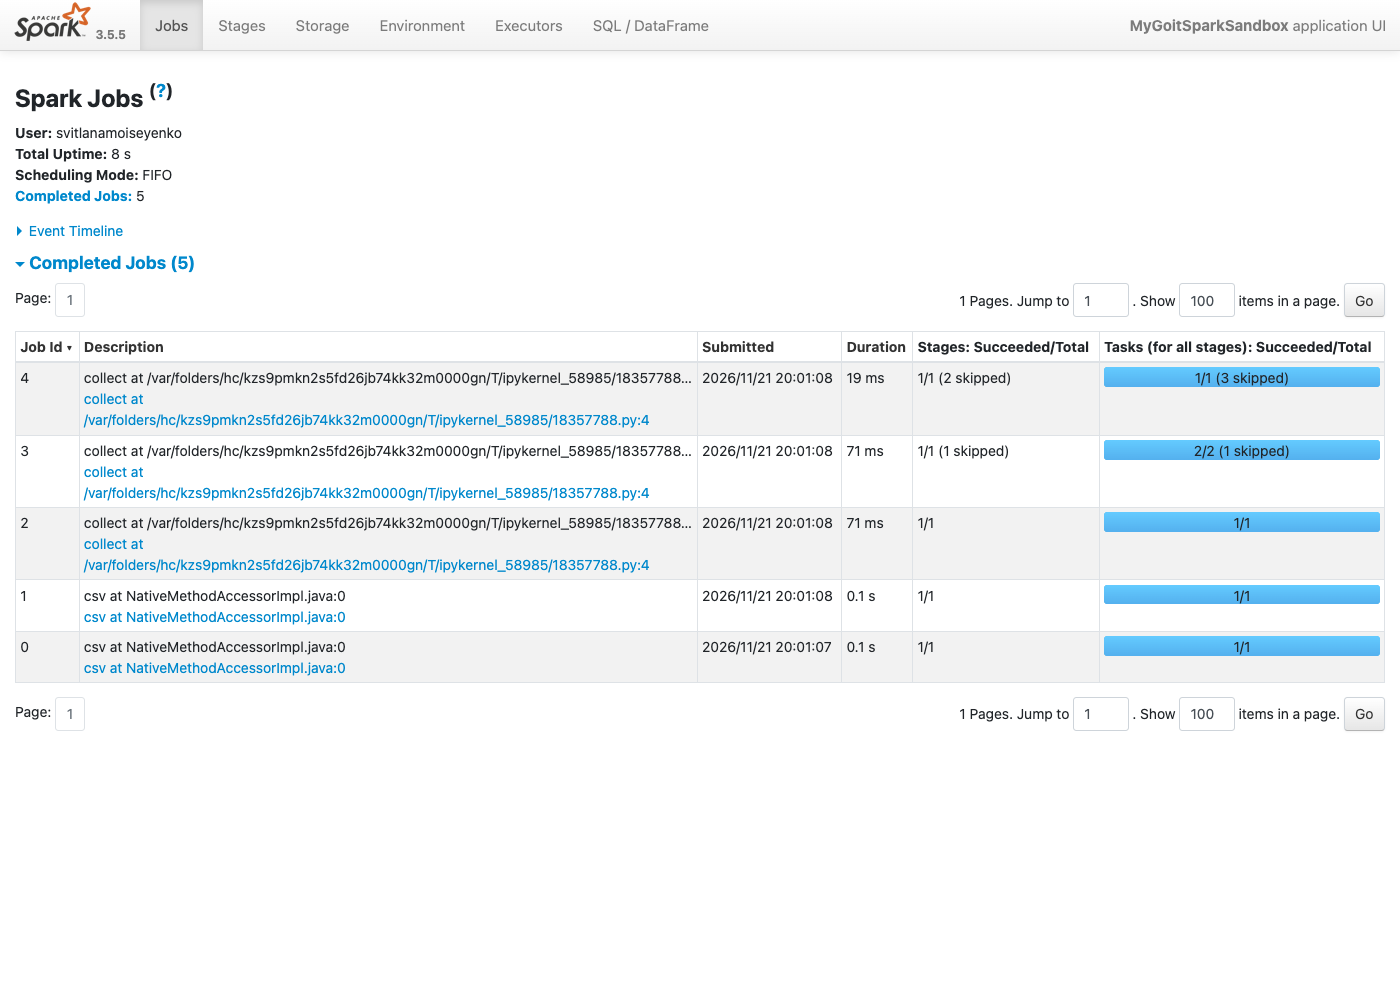

In [4]:
spark = create_session()

nuek_processed = build_processed(spark).where("count>2")
rows = nuek_processed.collect()
print(f"Рядків у результаті: {len(rows)}")

show_jobs(spark, 1)
spark.stop()

## Частина 2. Проміжний action `collect`

Рядків у результаті: 1


Частина 2: 8 Jobs (http://localhost:4040/jobs/)


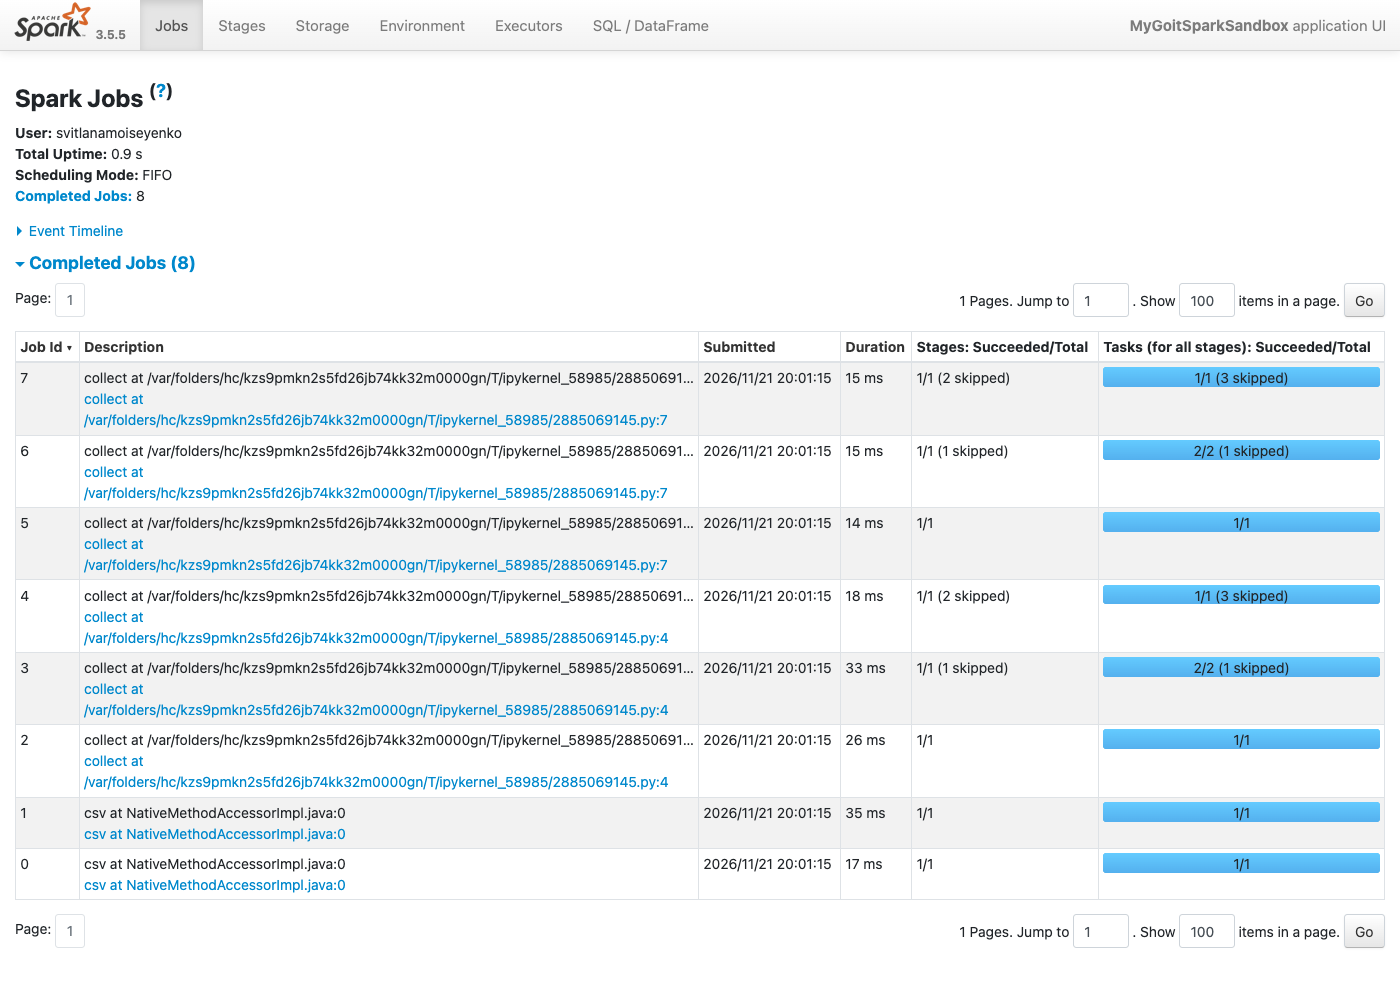

In [5]:
spark = create_session()

nuek_processed = build_processed(spark)
nuek_processed.collect()

nuek_processed = nuek_processed.where("count>2")
rows = nuek_processed.collect()
print(f"Рядків у результаті: {len(rows)}")

show_jobs(spark, 2)
spark.stop()

## Частина 3. Проміжний результат із `cache`

Рядків у результаті: 1


Частина 3: 7 Jobs (http://localhost:4040/jobs/)


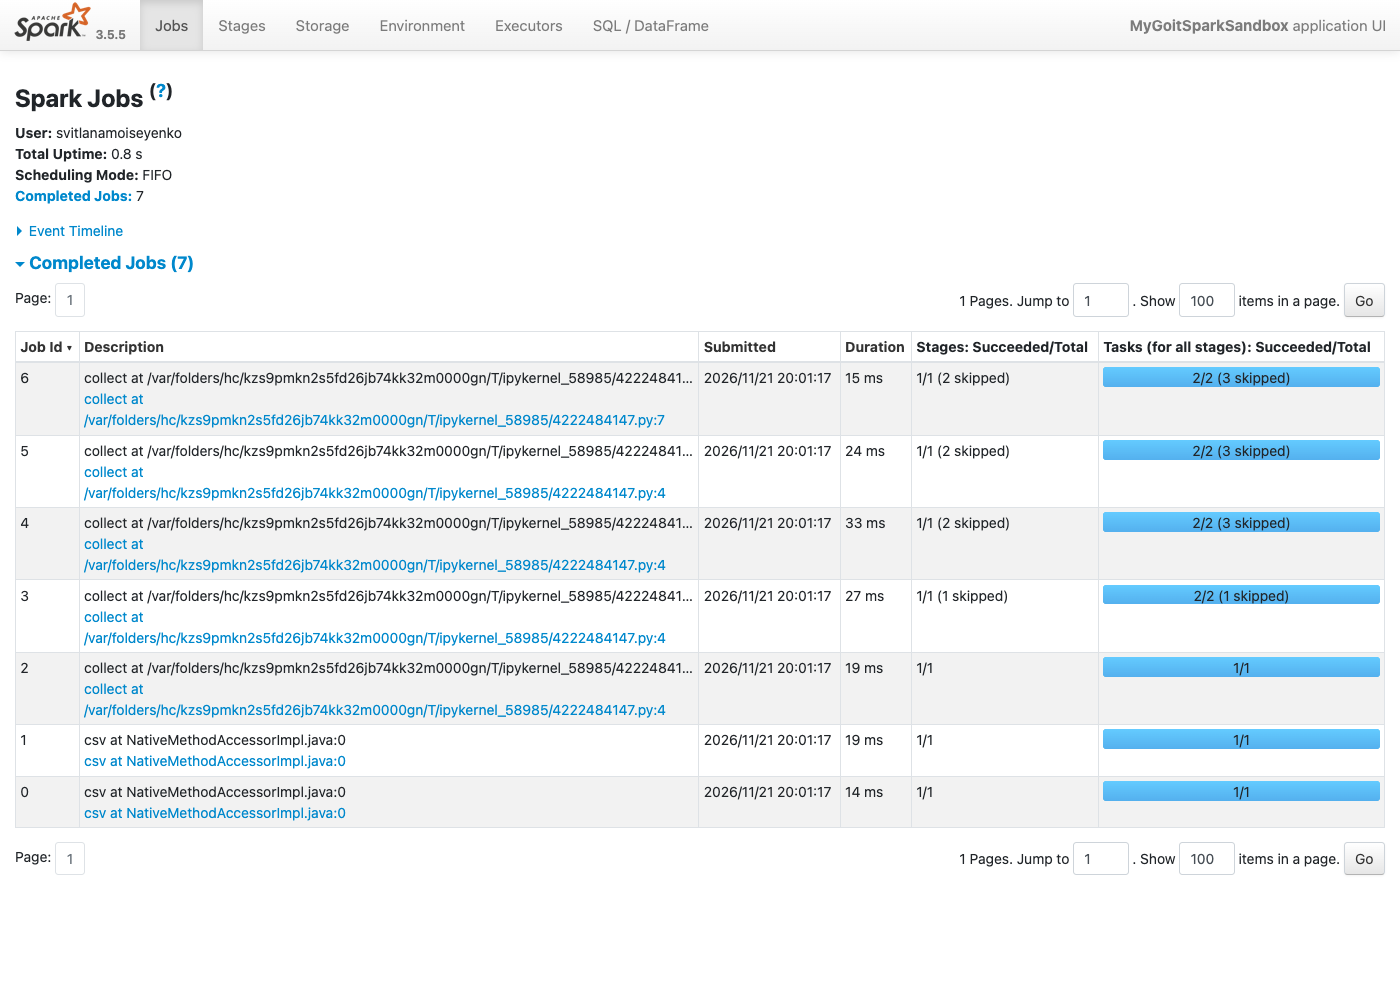

In [6]:
spark = create_session()

nuek_processed_cached = build_processed(spark).cache()
nuek_processed_cached.collect()

nuek_processed = nuek_processed_cached.where("count>2")
rows = nuek_processed.collect()
print(f"Рядків у результаті: {len(rows)}")

show_jobs(spark, 3)
nuek_processed_cached.unpersist()
spark.stop()

## Висновки

| Частина | Jobs | Склад |
|---|---|---|
| 1 | 5 | 2 (читання CSV) + 3 (`collect`) |
| 2 | 8 | 2 (читання CSV) + 3 (перший `collect`) + 3 (другий `collect`) |
| 3 | 7 | 2 (читання CSV) + 3 (перший `collect`) + 2 (другий `collect` з кешу) |

**Звідки 5 Jobs у частині 1.** `spark.read.csv` запускає 2 Jobs ще до будь-якого action: читання заголовка (`header`) і прохід по файлу для визначення типів (`inferSchema`). Єдиний `collect` дає ще 3 Jobs, бо в плані є два shuffle (`repartition(2)` і `groupBy`), а Adaptive Query Execution матеріалізує кожен shuffle окремим Job і лише після цього запускає фінальний: (1) скан CSV + фільтр + round-robin shuffle, (2) часткова агрегація + hash shuffle за `unit_id`, (3) фінальна агрегація, фільтр `count>2` і повернення результату. Доданий `where` — це трансформація (narrow), тому нових Jobs вона не створює.

**Чому в частині 2 на 3 Jobs більше.** Spark лінивий і не зберігає результати action. `where("count>2")` створює новий DataFrame з власним планом, тому другий `collect` заново проходить увесь lineage від читання файлу: знову 3 Jobs (два shuffle + фінальний). Один додатковий action = повне повторне обчислення.

**Чому з `cache()` Jobs стало менше.** Перший `collect` обчислює результат агрегації (ті самі 3 Jobs) і зберігає його в пам'яті. Другий `collect` уже не читає CSV і не виконує жодного shuffle: 1 Job матеріалізує кеш як стадію AQE (`TableCacheQueryStage`), ще 1 Job застосовує фільтр `count>2` до закешованих даних і повертає результат — 2 Jobs замість 3, а всі попередні стадії позначені як skipped. На великих даних виграш був би значно помітнішим: повторне читання й shuffle замінюються читанням із пам'яті. Після використання кеш звільняється через `unpersist()`.